# Phase 0 — environment check

This notebook checks that the three physics codes TurboML builds on run in our pinned environment, and shows what their outputs look like.

1. **pyCycle**: NASA's cycle-analysis code, running its full-size turbojet example.
2. **RadComp**: centrifugal-compressor meanline model, with a speed sweep in air.
3. **TurboFlow**: axial-turbine meanline model, at one operating point.

None of these are micro-turbojet results yet; they're plumbing checks. See `docs/LEARNING.md` for the vocabulary.

In [1]:
import os, subprocess, sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
os.chdir(ROOT)
print(subprocess.run([sys.executable, 'scripts/check_env.py'], capture_output=True, text=True).stdout)

python   3.11.17  (Linux-6.18.44-fc-v153-x86_64-with-glibc2.39)
numpy          2.3.5
scipy          1.17.1
pandas         2.3.3
openmdao       3.45.1
om-pycycle     4.4.1.dev0
radcompressor  1.0.1
turboflow      0.1.18
CoolProp       8.0.0
torch          2.14.1
gpytorch       1.15.2
botorch        0.18.1
pymoo          0.6.2
SALib          1.6.0
scikit-learn   1.9.1
pydantic       2.14.1

torch built for CUDA 13.0; torch.cuda.is_available() = False
  No GPU visible: NN/BoTorch work will run on CPU (fine for development).



## 1. pyCycle `simple_turbojet` (unmodified upstream example)
pyCycle reports in US units. Below we parse the summary line of each operating point and convert it to SI with `turboml.units`.

In [2]:
import pandas as pd
from turboml import units as u
proc = subprocess.run([sys.executable, str(ROOT / 'third_party/pycycle_examples/simple_turbojet.py')],
                      cwd=ROOT / 'runs', capture_output=True, text=True)
print('exit code', proc.returncode)
lines = proc.stdout.splitlines()
names = [l.split('POINT:')[1].strip() for l in lines if 'POINT:' in l]
rows = [lines[i + 1].split() for i, l in enumerate(lines) if 'Mach      Alt' in l]
df = pd.DataFrame([[float(x) for x in r] for r in rows], index=names,
                  columns=['Mach', 'Alt_ft', 'W_lbm_s', 'Fn_lbf', 'Fg_lbf', 'Fram_lbf', 'OPR', 'TSFC_lbm_lbf_h'])
si = pd.DataFrame({
    'Mach': df.Mach, 'alt_m': df.Alt_ft * u.FT_TO_M,
    'air_kg_s': df.W_lbm_s.map(u.lbm_s_to_kg_s), 'Fn_kN': df.Fn_lbf.map(u.lbf_to_N) / 1e3,
    'OPR': df.OPR,
    'TSFC_g_kN_s': df.TSFC_lbm_lbf_h.map(lambda t: u.tsfc_kg_per_N_s_to_g_per_kN_s(u.tsfc_lbm_per_lbf_h_to_kg_per_N_s(t))),
})
si.round(3)

exit code 0


,Mach,alt_m,air_kg_s,Fn_kN,OPR,TSFC_g_kN_s
DESIGN,0.0,0.0,66.829,52.489,13.500,22.618
OD0,0.0,0.0,64.767,48.930,12.859,22.197
OD1,0.2,1524.0,54.032,35.586,12.203,23.496


This is a **52 kN** engine with pressure ratio 13.5. Our target class is 0.05–1 kN with pressure ratio around 2–4. Phase 1 re-builds this model at micro scale.

## 2. RadComp: compressor speed sweep in air
This uses the Schiffmann & Favrat (2010) impeller, a 20 mm-diameter heat-pump compressor (not a turbojet compressor), at fixed mass flow. Pressure ratio rises with tip speed, as Euler's turbine equation predicts.

,N_krpm,U2_m_s,PR,eta_is,valid
0,140.0,146.608,NaN,NaN,False
1,150.0,157.080,1.000,0.006,True
2,160.0,167.552,1.028,0.379,True
3,170.0,178.024,1.059,0.563,True
4,180.0,188.496,1.093,0.669,True
5,190.0,198.968,1.131,0.737,True
6,200.0,209.440,1.173,0.782,True
7,210.0,219.911,1.219,0.812,True
8,220.0,230.383,1.269,0.834,True
9,230.0,240.855,1.323,0.850,True


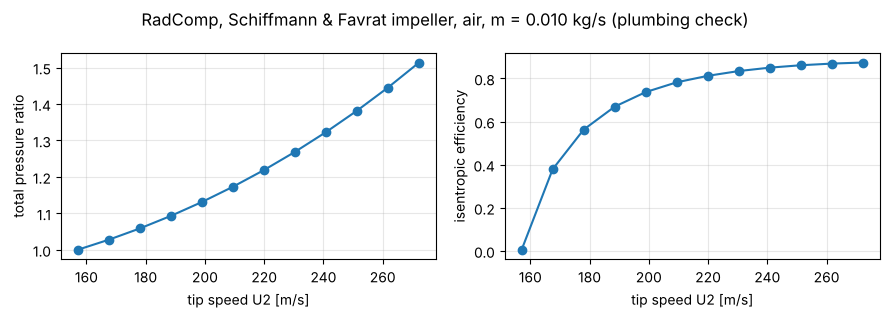

In [3]:
import numpy as np, yaml, matplotlib.pyplot as plt
from radcompressor.compressor import Compressor
from radcompressor.condition import OperatingCondition
from radcompressor.geometry import Geometry
from radcompressor.thermo import CoolPropFluid
db = yaml.safe_load((ROOT / 'third_party/radcomp_known_compressors.yml').read_text())
geom = Geometry.from_dict(next(d for d in db if d['name'] == 'Schiffmann and Favrat')['geom'])
in0 = CoolPropFluid('Air').thermo_prop('PT', u.ISA_SEA_LEVEL_P_PA, u.ISA_SEA_LEVEL_T_K)
res = []
for n_rpm in np.arange(140e3, 261e3, 10e3):
    c = Compressor(geom, OperatingCondition(in0=in0, fld=in0.fld, m=0.010, n_rot=u.rpm_to_rad_s(n_rpm)))
    ok = c.calculate()
    res.append((n_rpm / 1e3, u.rpm_to_rad_s(n_rpm) * geom.r4, c.PR if ok else np.nan, c.eff if ok else np.nan, ok))
rc = pd.DataFrame(res, columns=['N_krpm', 'U2_m_s', 'PR', 'eta_is', 'valid'])
fig, ax = plt.subplots(1, 2, figsize=(9, 3.2))
ax[0].plot(rc.U2_m_s, rc.PR, 'o-'); ax[0].set(xlabel='tip speed U2 [m/s]', ylabel='total pressure ratio')
ax[1].plot(rc.U2_m_s, rc.eta_is, 'o-'); ax[1].set(xlabel='tip speed U2 [m/s]', ylabel='isentropic efficiency')
for a in ax: a.grid(alpha=.3)
fig.suptitle('RadComp, Schiffmann & Favrat impeller, air, m = 0.010 kg/s (plumbing check)'); fig.tight_layout()
rc.round(3)

Invalid rows (NaN) are points where RadComp marks the operating point infeasible. Later phases record such failures as training data for the feasibility classifier instead of discarding them.

## 3. TurboFlow: single-stage axial turbine
TurboFlow's own example, using the NASA cold-air turbine geometry of Kofskey et al. (1972). TurboFlow ships measured data for this turbine, so it's our candidate turbine validation case for Phase 2.

In [4]:
os.environ.setdefault('MPLBACKEND', 'Agg')
import turboflow as tf
cfg = tf.load_config(str(ROOT / 'third_party/turboflow_one_stage_config.yaml'), print_summary=False)
solver = tf.compute_performance(cfg['operation_points'], cfg, export_results=False, stop_on_failure=True)[0]
o = solver.problem.results['overall']
pd.Series({k: float(o[k].iloc[0]) for k in ['efficiency_ts', 'efficiency_tt', 'mass_flow_rate', 'PR_ts', 'power']}).round(4)

--------------------------------------------------------------------------------
 Summary of operation points scheduled for simulation
--------------------------------------------------------------------------------
   Index    Fluid   angle_in        T0_in        p0_in        p_out        omega
                       [deg]       [degC]        [kPa]        [kPa]        [RPM]
       1      air        0.0        22.45       138.00        60.05        15537
--------------------------------------------------------------------------------

 Computing operation point 1 of 1
--------------------------------------------------------------------------------
 Operating point: 
--------------------------------------------------------------------------------
 Fluid:                    air
 Flow angle in:            0.00 deg
 Total temperature in:     22.45 degC
 Total pressure in:        1.380 bar
 Static pressure out:      0.601 bar
 Angular speed:            15536.7 RPM
--------------------------

               2              1            7.670819e-02            0.000000e+00 
               3              1            7.670819e-02            0.000000e+00 


               4              2            7.696719e-03            7.660169e-02 
               5              2            6.541517e-03            4.836232e-02 
               6              2            4.588381e-04            2.493150e-02 
               7              2            8.200853e-05            1.194527e-03 


               8              2            5.450792e-06            2.818084e-04 
               9              2            2.771784e-06            1.586985e-05 
              10              2            2.933481e-07            6.816299e-06 


              11              2            4.257264e-09            6.330873e-07 
              12              2            4.055117e-10            8.660571e-09 
              13              2            4.055117e-10            0.000000e+00 
              13              2            4.055117e-10            0.000000e+00 
--------------------------------------------------------------------------------
Success: True
Exit message: The solution converged.
Solution time: 3.125 seconds
--------------------------------------------------------------------------------


--------------------------------------------------------------------------------
               Final summary of performance analysis calculations               
--------------------------------------------------------------------------------
 Simulation successful for 1 out of 1 points
 Average calculation time per operation point: 3.125 seconds
 Minimum calculation time of all operation points: 3.125 seconds
 Maximum calculat

efficiency_ts         79.1203
efficiency_tt         92.5743
mass_flow_rate         2.7371
PR_ts                  2.2980
power             135956.6724
dtype: float64

## Summary
All three codes run in the pinned environment. The values above are also asserted as regression baselines in `tests/test_external_tools.py`. Next is Phase 1: the cycle model at micro-turbojet scale, plus an independent 0-D cross-check model.